# 🐙 玫瑰線章魚小怪獸 2.0

**成大 F74146115 資訊118 謝承祐**｜TAICA 生成式 AI 第一週作業（第十一週補交版）

這份作業用 **玫瑰線（Rose Curve）** 拼出一隻章魚小怪獸：觸手、腮紅、頭上的斑點、皇冠、海底的珊瑚，全部都是玫瑰線變出來的。

### 這次補交新增了什麼

| | 第一週原版 | 補交版 |
|---|---|---|
| 表情 | 開心、難過、驚訝、生氣 | 再加 **想睡**、**眨眼** |
| 配件 | 無 | **皇冠**（上半圓玫瑰線）、**泡泡** |
| 配色 | 固定紫色 | **色相滑桿**：一個數字換整套配色 |
| 動態 | 靜態圖 | **游泳動畫**：觸手擺動、頭上下浮動、會眨眼，另存成 GIF |
| 合照 | 四張分開的圖 | **海底場景**：章魚家族、玫瑰線珊瑚、海草、海星 |

---

## 0. 標準開場：老師的固定 4 行

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. 什麼是玫瑰線？

玫瑰線是用**極座標**定義的曲線：

$$r(\theta) = a\cos(k\theta)$$

- $a$：花瓣長度
- $k$：決定花瓣數量
  - $k$ 為**奇數**時，有 $k$ 片花瓣
  - $k$ 為**偶數**時，有 $2k$ 片花瓣

`plt.plot` 需要直角座標，所以要轉換：

$$x = r\cos\theta,\qquad y = r\sin\theta$$

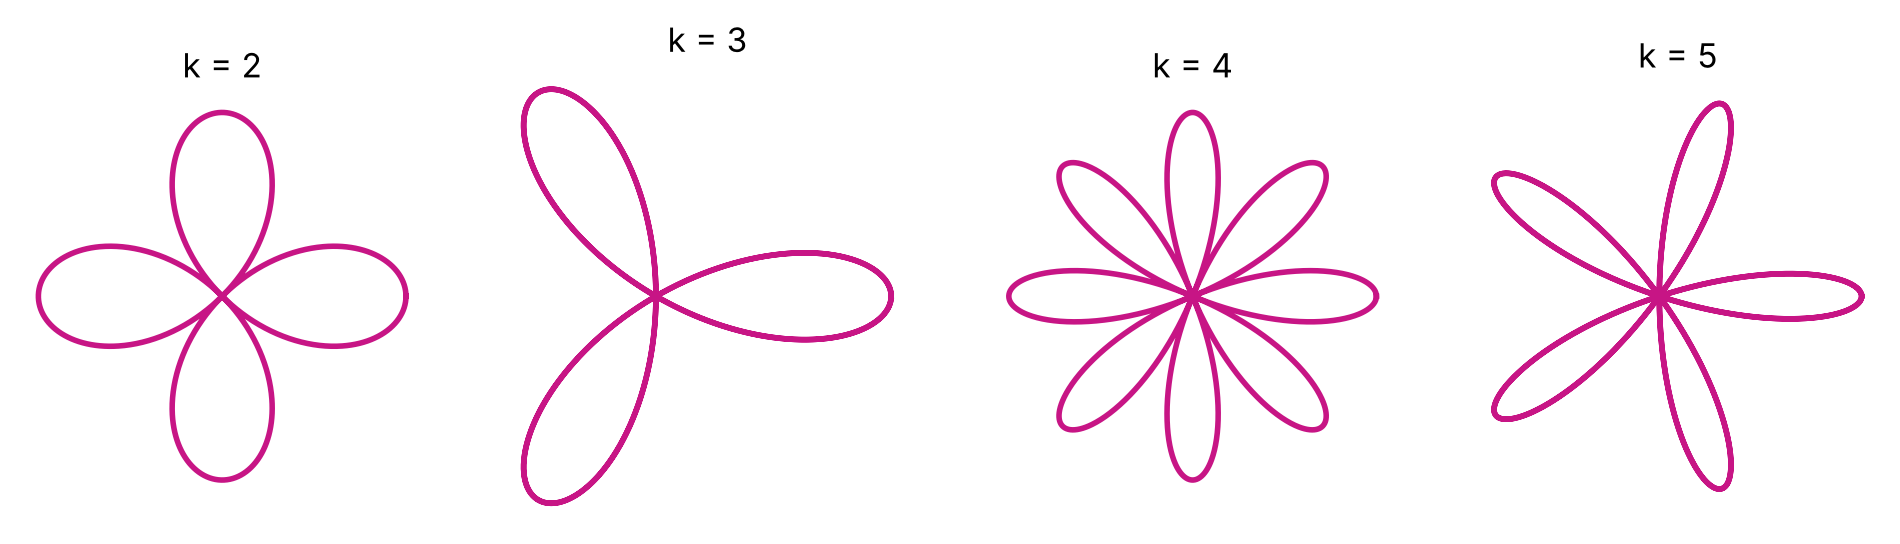

In [2]:
def rose(k, a=1.0, n=2000):
    """回傳玫瑰線 r = a·cos(kθ) 的 (x, y) 座標"""
    theta = np.linspace(0, 2*np.pi, n)
    r = a * np.cos(k * theta)
    return r * np.cos(theta), r * np.sin(theta)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, k in zip(axes, [2, 3, 4, 5]):
    x, y = rose(k)
    ax.plot(x, y, lw=2, color='mediumvioletred')
    ax.set_title(f'k = {k}')
    ax.set_aspect('equal')
    ax.axis('off')
plt.show()

觀察：$k=3, 5$ 分別有 3、5 片花瓣；$k=2, 4$ 分別有 4、8 片花瓣。

## 2. 把花瓣變成觸手 🦑

章魚的觸手只需要長在**下半部**，所以做三個改動：

1. 只取 $\theta \in [\pi, 2\pi]$（下半圓）
2. 加上絕對值，讓 $r \ge 0$，花瓣就不會翻到上半部
3. 把 $\cos$ 換成 $\sin$（$r=a\sin(k\theta)$ 也是玫瑰線，只是轉了一個角度），這樣 $\theta=\pi$ 和 $2\pi$ 剛好是 $r=0$，兩側不會出現半片花瓣

$$r(\theta) = L\,\lvert\sin(k\theta)\rvert,\qquad \pi \le \theta \le 2\pi$$

這樣在下半圓裡剛好有 **$k$ 條完整的觸手**。

**讓觸手捲起來：** 每個點再依「離中心的距離」旋轉一個角度，越外側轉越多：

$$\theta' = \theta + t \cdot r^2 \cos\theta + w \cdot r^2$$

- $t$ 是捲曲程度，$t=0$ 時就是原本的玫瑰線
- $r^2$：觸手尖端轉得比根部多，才會「捲」而不是整條轉
- $\cos\theta$：左右兩側方向相反、正下方幾乎不轉，所以章魚保持左右對稱
- $w$ 是**補交版新增**的「擺動量」：少了 $\cos\theta$，所有觸手往同一個方向偏，第 6 節的動畫就是讓 $w$ 左右來回變化

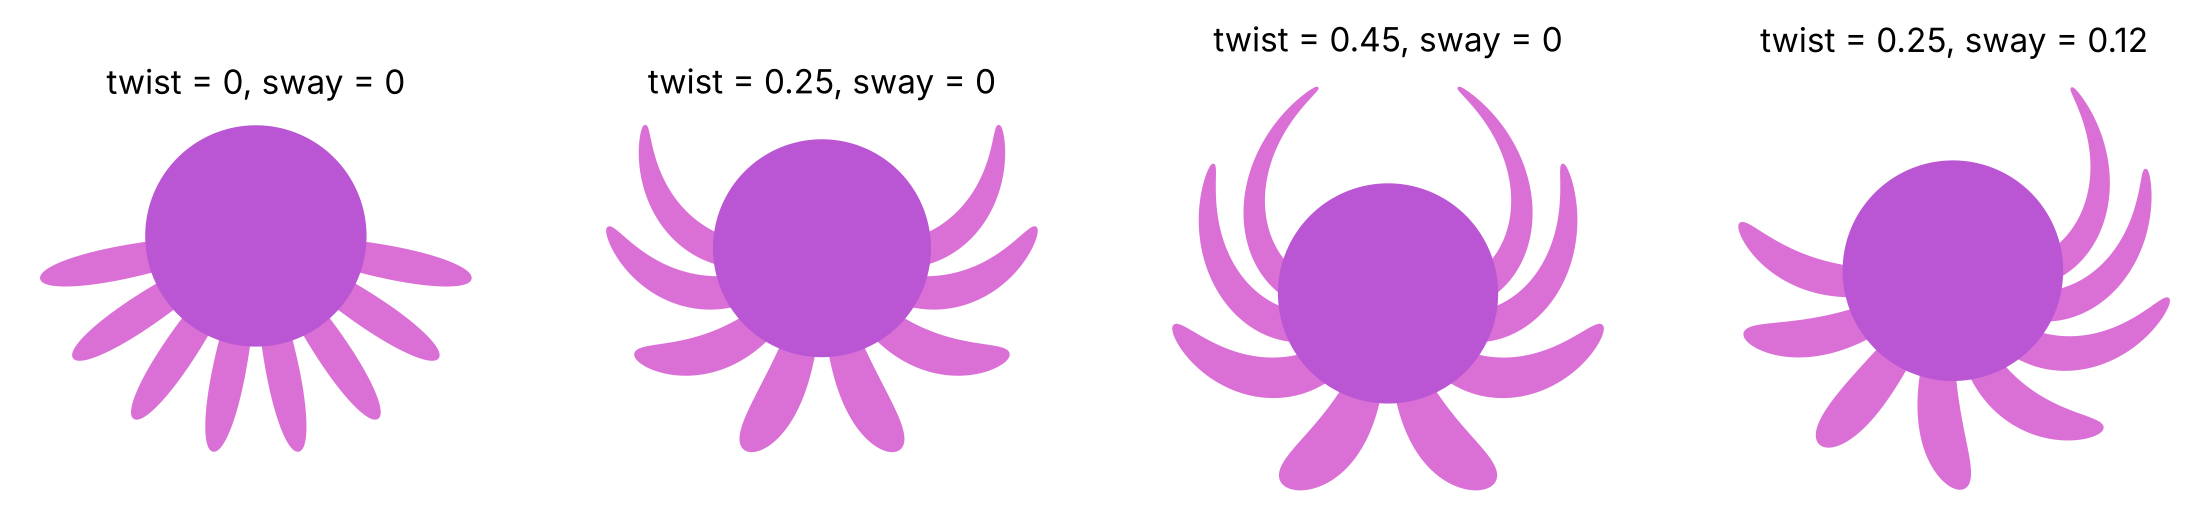

In [3]:
def tentacles(k, length=1.8, twist=0.0, sway=0.0, n=3000):
    """下半圓玫瑰線 → k 條觸手；回傳每條觸手的 (x, y)"""
    theta = np.linspace(np.pi, 2*np.pi, n)
    r = length * np.abs(np.sin(k * theta))
    theta2 = theta + twist * r**2 * np.cos(theta) + sway * r**2   # 對稱捲曲 + 同向擺動
    x, y = r * np.cos(theta2), r * np.sin(theta2)
    # 在 r = 0 的地方切開，每一段就是一條觸手（分開填色才不會黏在一起）
    cuts = np.where(np.diff(np.sign(np.sin(k * theta))) != 0)[0] + 1
    return [(xs, ys) for xs, ys in zip(np.split(x, cuts), np.split(y, cuts))]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (t, w) in zip(axes, [(0, 0), (0.25, 0), (0.45, 0), (0.25, 0.12)]):
    for x, y in tentacles(8, twist=t, sway=w):
        ax.fill(np.r_[0, x, 0], np.r_[0, y, 0], color='orchid')
    c = np.linspace(0, 2*np.pi, 200)
    ax.fill(0.9*np.cos(c), 0.9*np.sin(c), color='mediumorchid')   # 先放一顆頭蓋住根部
    ax.set_title(f'twist = {t}, sway = {w}')
    ax.set_aspect('equal')
    ax.axis('off')
plt.show()

## 3. 調色盤：一個色相數字換整套配色 🎨

原版的顏色是寫死的四個名字（`mediumorchid`、`darkorchid`…）。補交版改用 **HLS 色彩空間**：

- **H**（hue，色相）：$0 \sim 1$ 繞色環一圈，$0$ 紅、$0.33$ 綠、$0.66$ 藍、$0.8$ 左右是原版的紫色
- **L**（lightness，亮度）、**S**（saturation，飽和度）：每個部位固定

| 部位 | L | S | 效果 |
|---|---|---|---|
| 頭 | 0.62 | 0.55 | 中等亮度 |
| 觸手 | 0.45 | 0.55 | 比頭暗一點，看得出前後 |
| 眼睛、嘴巴 | 0.18 | 0.60 | 很暗，當線條色 |
| 斑點 | 0.80 | 0.55 | 很亮，像花紋 |

因為只有 H 在變，**明暗關係永遠不變**，不管滑到哪個顏色，章魚都不會「糊成一團」。

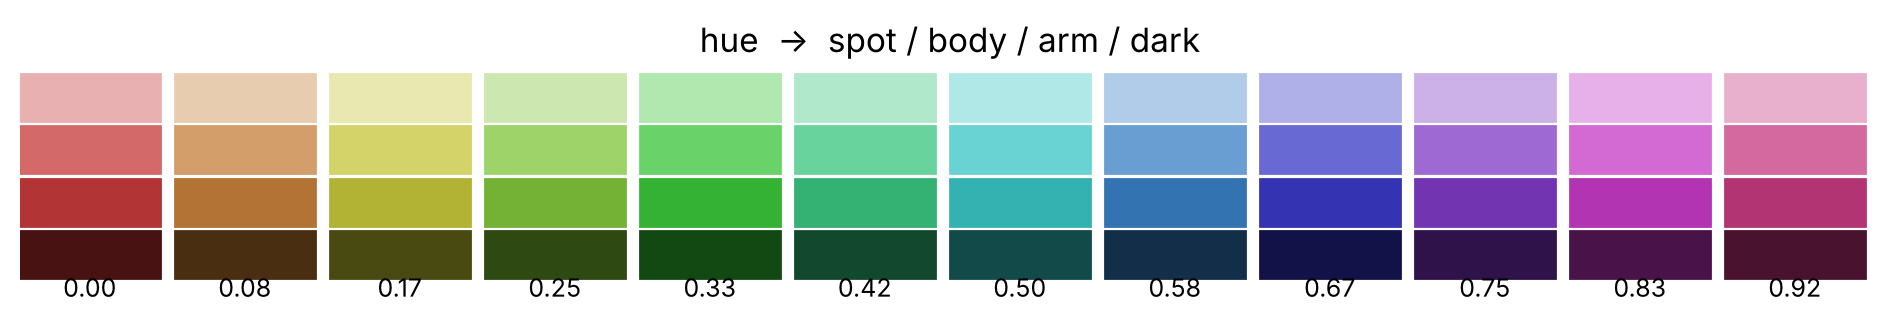

In [4]:
import colorsys

def palette(hue):
    """依色相 hue（0~1）產生一整套章魚配色"""
    c = lambda l, s: colorsys.hls_to_rgb(hue % 1, l, s)
    return dict(body=c(0.62, 0.55), arm=c(0.45, 0.55),
                dark=c(0.18, 0.60), spot=c(0.80, 0.55))

fig, ax = plt.subplots(figsize=(12, 1.6))
for i, h in enumerate(np.linspace(0, 1, 13)[:-1]):
    for j, part in enumerate(['spot', 'body', 'arm', 'dark']):
        ax.add_patch(plt.Rectangle((i, 3 - j), 0.9, 0.9, color=palette(h)[part]))
    ax.text(i + 0.45, -0.35, f'{h:.2f}', ha='center', fontsize=9)
ax.set_xlim(0, 12); ax.set_ylim(-0.7, 4)
ax.set_title('hue  ->  spot / body / arm / dark')
ax.axis('off')
plt.show()

## 4. 組裝小怪獸

| 部位 | 數學 |
|---|---|
| 觸手 | 下半圓玫瑰線 $L\lvert\sin(k\theta)\rvert$ + 捲曲 + 擺動 |
| 頭 | 橢圓 $x=R\cos\theta,\ y=1.15R\sin\theta$ |
| 眼睛 | 橢圓 + 瞳孔；**想睡／眨眼**時改成拋物線 $y=-c\,x^2$ 的閉眼弧線 |
| 嘴巴 | 拋物線 $y = c\,x^2$，$c$ 的正負決定開心或難過 |
| 腮紅、斑點 | 迷你玫瑰線 $r = a\cos(5\theta)$ |
| **皇冠**（新） | **上半圓**玫瑰線 $r = R_0 + h\lvert\sin(5\theta)\rvert^3,\ 0\le\theta\le\pi$：觸手的作法翻到上面，加一個底座半徑 $R_0$；三次方讓尖角變細，再點上三顆寶石 |
| **泡泡**（新） | 三個由小到大的圓，加一個白色反光點 |

補交版把整隻章魚寫成 `draw_octopus(ax, ..., cx, cy, s)`：可以指定**畫在哪張圖、中心在哪、縮放多少**。這樣後面的動畫和海底場景才能重複使用同一隻章魚。

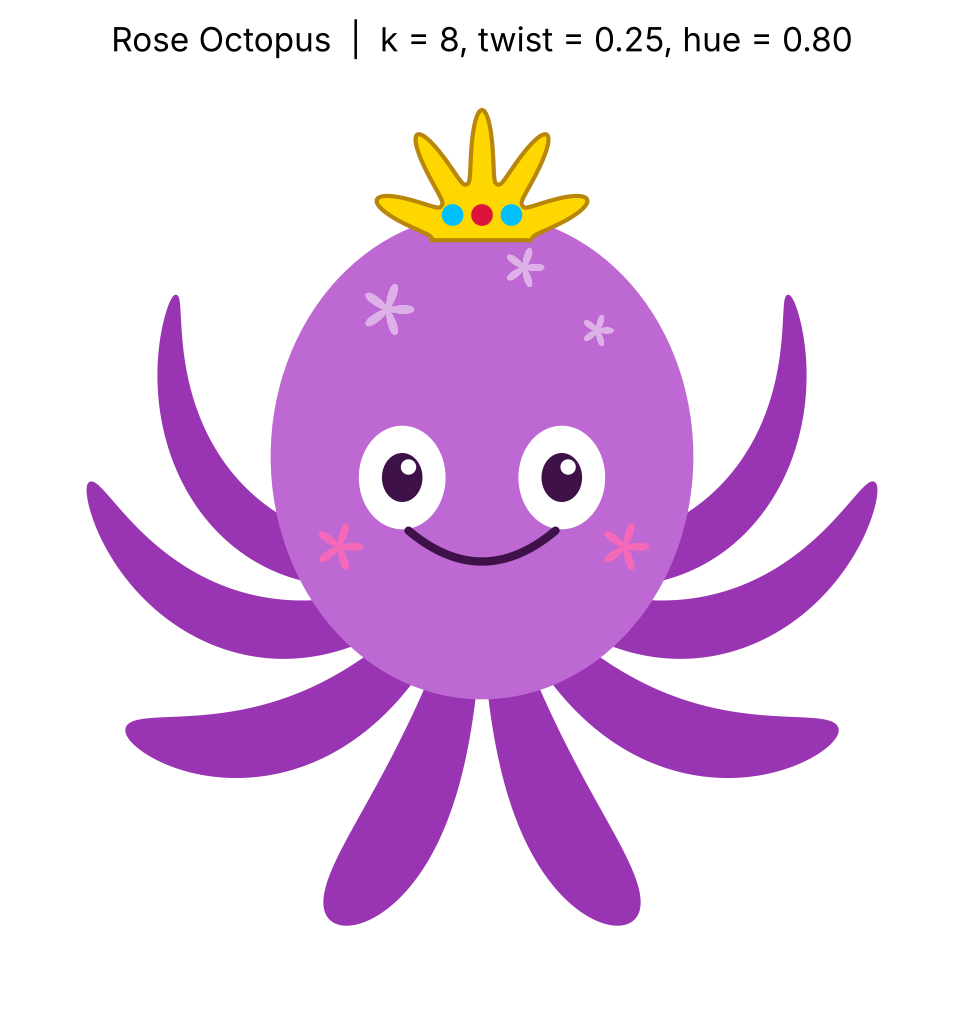

In [5]:
BLUSH = 'hotpink'
GOLD  = 'gold'
MOODS = ['開心', '難過', '驚訝', '生氣', '想睡', '眨眼']
ACCESSORIES = ['無', '皇冠', '泡泡', '皇冠+泡泡']

def draw_octopus(ax, k=8, twist=0.25, mood='開心', hue=0.8, accessory='無',
                 cx=0.0, cy=0.0, s=1.0, sway=0.0, blink=0.0, z=0):
    """把章魚畫在 ax 上；(cx, cy) 是中心，s 是縮放，blink=1 代表眼睛全閉"""
    P = palette(hue)
    T = lambda x, y: (cx + s*np.asarray(x), cy + s*np.asarray(y))   # 平移 + 縮放
    fill = lambda x, y, **kw: ax.fill(*T(x, y), **kw)
    line = lambda x, y, lw, **kw: ax.plot(*T(x, y), lw=lw*s, solid_capstyle='round', **kw)
    t = np.linspace(0, 2*np.pi, 120)

    # 觸手、頭
    for x, y in tentacles(k, length=1.9, twist=twist, sway=sway):
        fill(np.r_[0, x, 0], np.r_[0, y, 0] - 0.1, color=P['arm'], zorder=z+1)
    fill(1.0*np.cos(t), 1.15*np.sin(t) + 0.35, color=P['body'], zorder=z+2)

    # 頭上斑點（迷你玫瑰線）
    for sx, sy, a in [(-0.45, 1.05, 0.12), (0.2, 1.25, 0.09), (0.55, 0.95, 0.07)]:
        x, y = rose(5, a=a)
        fill(x + sx, y + sy, color=P['spot'], zorder=z+3)

    # 眼睛
    for side in (-1, 1):
        ex, ey = 0.38 * side, 0.25
        closed = (mood == '想睡') or (mood == '眨眼' and side == 1) or blink >= 0.99
        if closed:                                   # 閉眼：向下彎的拋物線
            x = np.linspace(-0.17, 0.17, 50)
            line(ex + x, ey - 4*x**2 + 0.04, 4, color=P['dark'], zorder=z+4)
        else:
            sq = 1 - 0.9*blink                       # 眨眼動畫：眼睛上下壓扁
            fill(ex + 0.2*np.cos(t), ey + 0.24*sq*np.sin(t), color='white', zorder=z+3)
            py = ey - 0.05 if mood == '難過' else ey
            fill(ex + 0.09*np.cos(t), py + 0.11*sq*np.sin(t), color=P['dark'], zorder=z+4)
            fill(ex + 0.03 + 0.03*np.cos(t), py + 0.05*sq + 0.03*sq*np.sin(t), color='white', zorder=z+5)
        bx = np.array([ex - 0.2*side, ex + 0.2*side])
        if mood == '生氣':                           # 斜眉毛
            line(bx, [0.52, 0.62] if side < 0 else [0.62, 0.52], 4, color=P['dark'], zorder=z+6)
        if mood == '難過':                           # 八字眉
            line(bx, [0.62, 0.55] if side < 0 else [0.55, 0.62], 4, color=P['dark'], zorder=z+6)

    # 嘴巴
    x = np.linspace(-0.35, 0.35, 100)
    if mood in ('開心', '眨眼'):
        line(x, 1.2*x**2 - 0.15, 3, color=P['dark'], zorder=z+4)
    elif mood == '難過':
        line(x*0.86, -1.2*(x*0.86)**2 - 0.1, 3, color=P['dark'], zorder=z+4)
    elif mood == '驚訝':
        fill(0.12*np.cos(t), 0.16*np.sin(t) - 0.2, color=P['dark'], zorder=z+4)
    elif mood == '生氣':
        line(x*0.86, 0.08*np.sin(20*x*0.86) - 0.18, 3, color=P['dark'], zorder=z+4)
    elif mood == '想睡':                             # 小小的 o 型嘴 + Zzz
        fill(0.06*np.cos(t), 0.07*np.sin(t) - 0.18, color=P['dark'], zorder=z+4)
        for i, (zx, zy) in enumerate([(0.75, 1.15), (0.98, 1.42), (1.25, 1.72)]):
            ax.text(*T(zx, zy), 'Z', fontsize=(12 + 5*i)*s, fontweight='bold',
                    color=P['dark'], zorder=z+7)

    # 腮紅（迷你玫瑰線）
    for side in (-1, 1):
        x, y = rose(5, a=0.11)
        fill(x + 0.68*side, y - 0.08, color=BLUSH, alpha=0.7, zorder=z+3)

    # 配件
    if '皇冠' in accessory:                          # 上半圓玫瑰線 r = R0 + h|sin(5θ)|
        th = np.linspace(0, np.pi, 400)
        r = 0.28 + 0.34*np.abs(np.sin(5*th))**3      # 三次方讓尖角變細，比較像皇冠
        fill(np.r_[0.85*r*np.cos(th), 0.24], np.r_[r*np.sin(th), 0] + 1.38,
             color=GOLD, ec='darkgoldenrod', lw=1.5*s, zorder=z+6)
        for jx, jc in [(-0.14, 'deepskyblue'), (0.0, 'crimson'), (0.14, 'deepskyblue')]:
            fill(jx + 0.045*np.cos(t), 1.5 + 0.045*np.sin(t), color=jc, zorder=z+7)
    if '泡泡' in accessory:
        for bx_, by_, br in [(1.08, 0.05, 0.06), (1.22, 0.38, 0.09), (1.38, 0.82, 0.13)]:
            fill(bx_ + br*np.cos(t), by_ + br*np.sin(t), fc=(0.85, 0.95, 1, 0.35),
                 ec='steelblue', lw=1.5*s, zorder=z+7)
            fill(bx_ - br*0.35 + br*0.2*np.cos(t), by_ + br*0.35 + br*0.2*np.sin(t),
                 color='white', zorder=z+8)


def octopus(k=8, twist=0.25, mood='開心', hue=0.8, accessory='無', show_title=True):
    """畫一張只有一隻章魚的圖"""
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_octopus(ax, k, twist, mood, hue, accessory)
    if show_title:
        ax.set_title(f'Rose Octopus  |  k = {k}, twist = {twist}, hue = {hue:.2f}', fontsize=12)
    ax.set_aspect('equal')
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.axis('off')
    plt.show()

octopus(accessory='皇冠')

### 新表情與配件一覽

上排是原版的四種表情，下排是補交版新增的兩種表情和兩種配件。

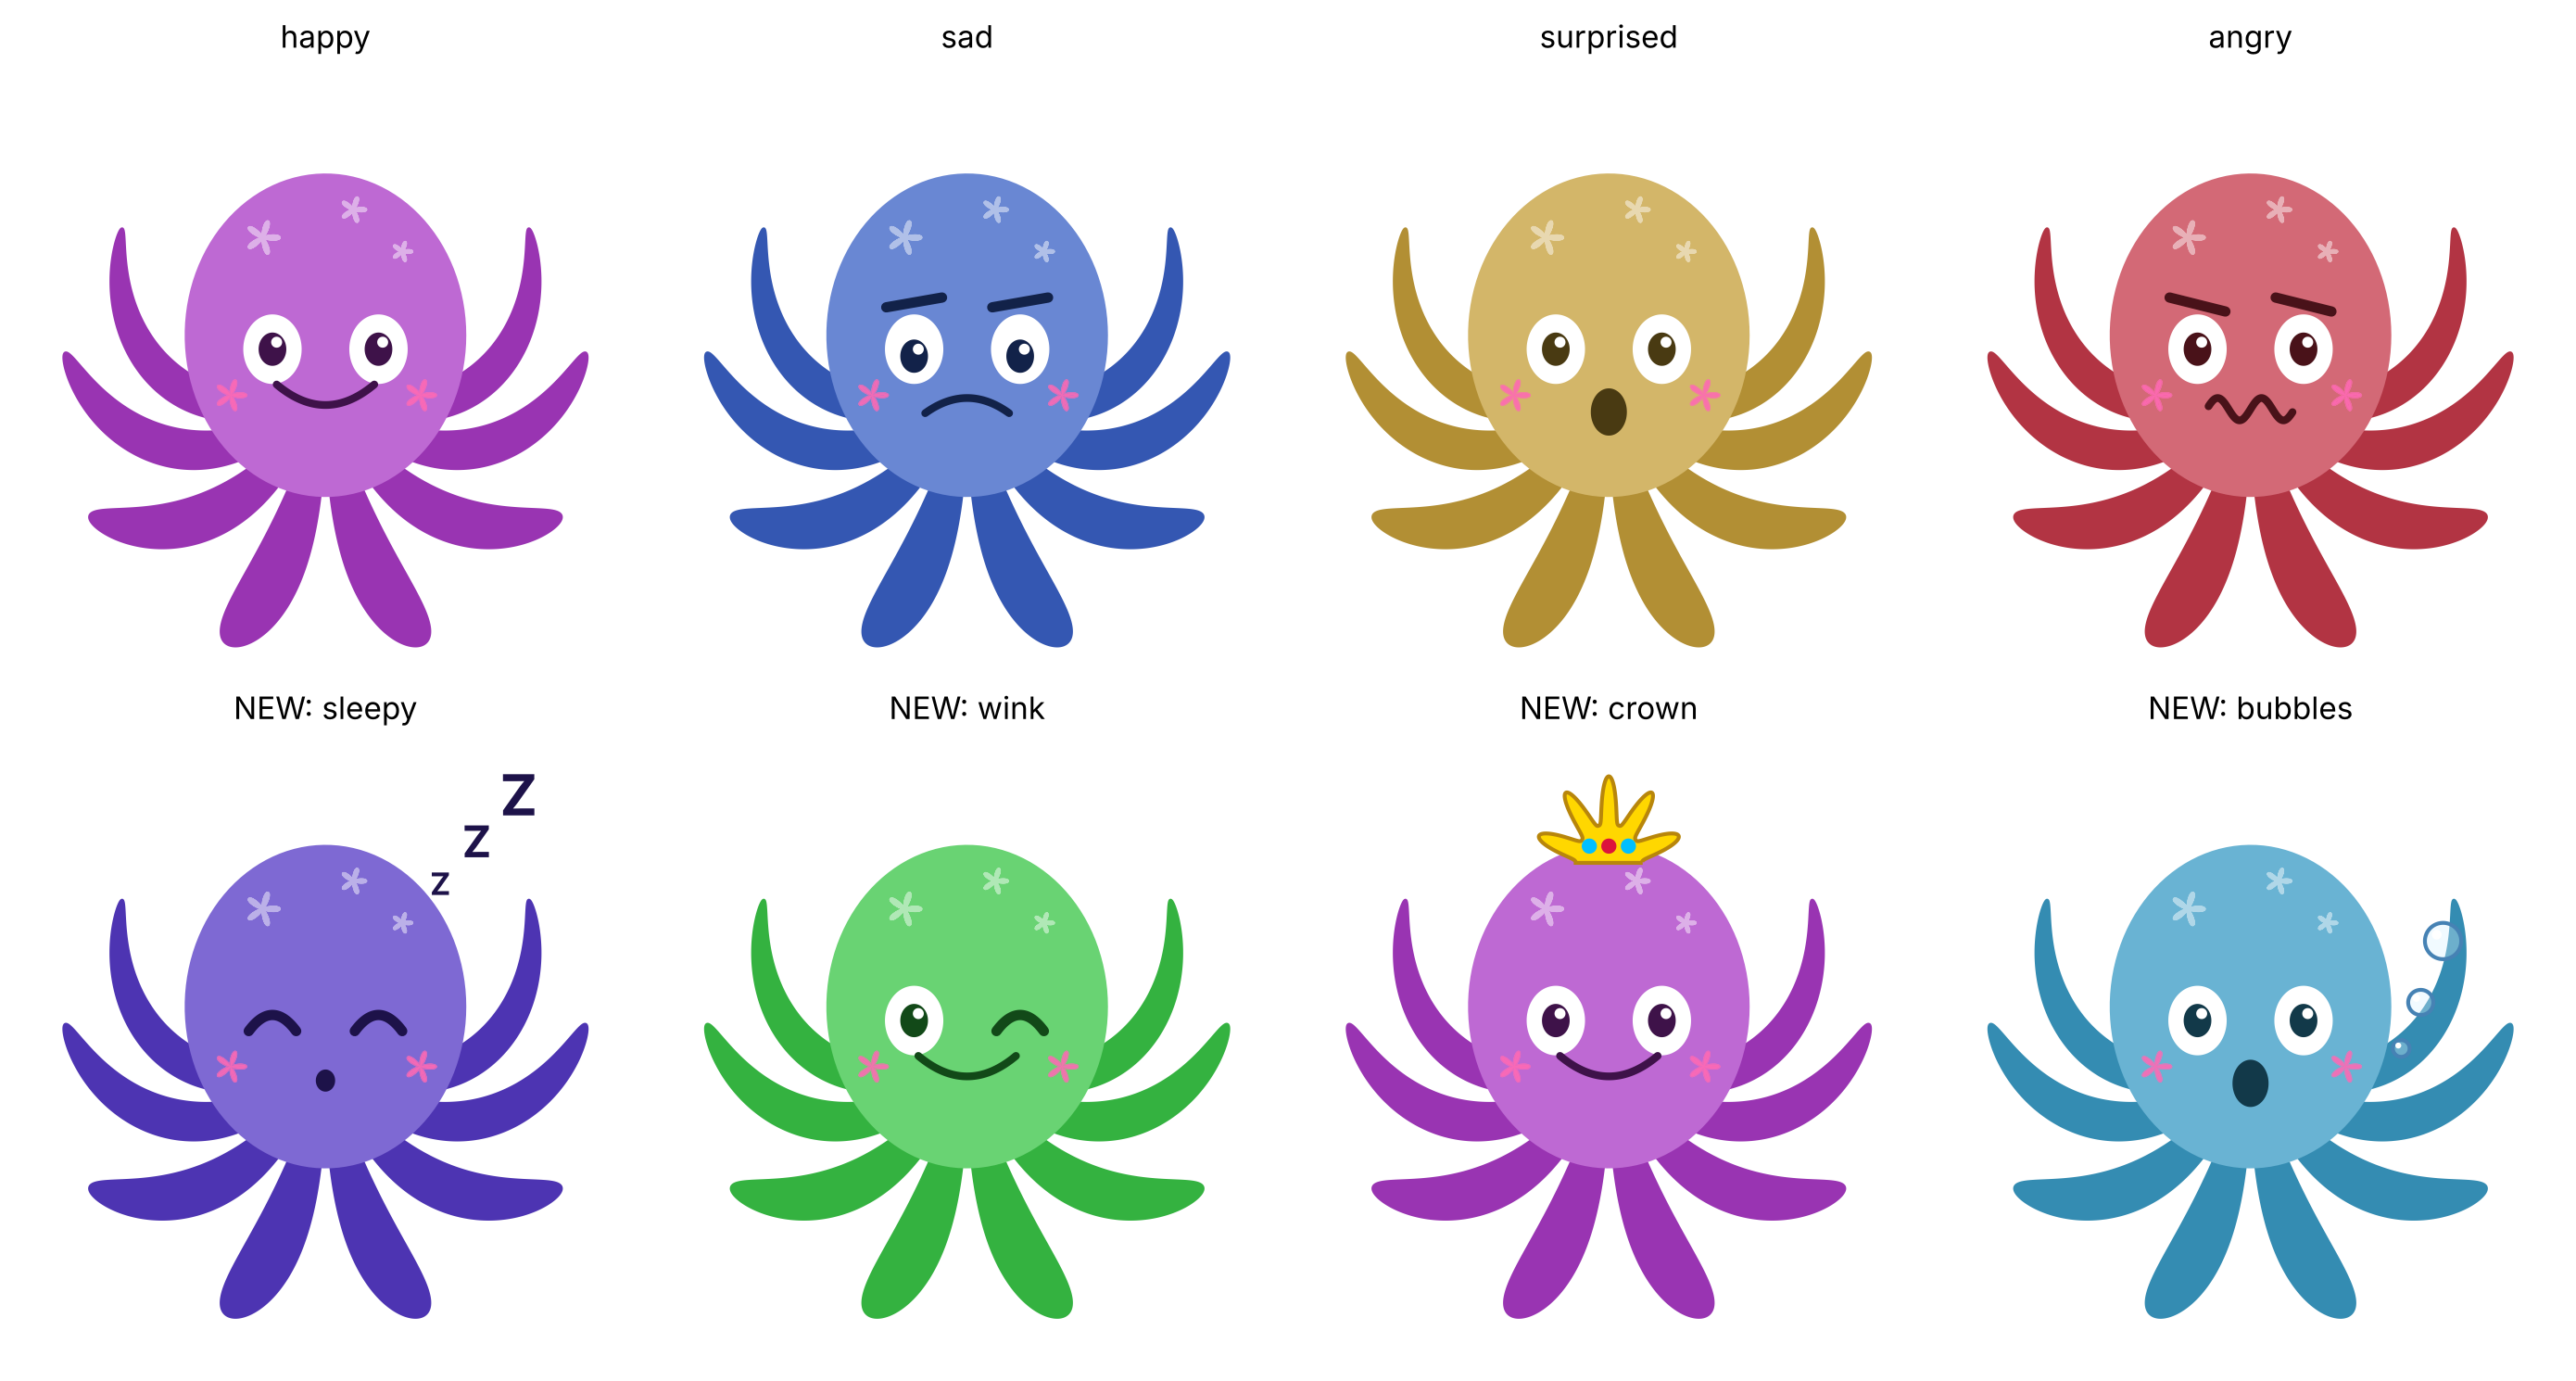

In [6]:
combos = [('開心', '無', 0.80), ('難過', '無', 0.62), ('驚訝', '無', 0.12), ('生氣', '無', 0.98),
          ('想睡', '無', 0.70), ('眨眼', '無', 0.35), ('開心', '皇冠', 0.80), ('驚訝', '泡泡', 0.55)]
labels = ['happy', 'sad', 'surprised', 'angry',
          'NEW: sleepy', 'NEW: wink', 'NEW: crown', 'NEW: bubbles']
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, (m, acc, h), lab in zip(axes.flat, combos, labels):
    draw_octopus(ax, k=8, twist=0.25, mood=m, hue=h, accessory=acc)
    ax.set_title(lab, fontsize=12)
    ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.3); ax.axis('off')
plt.tight_layout()
plt.show()

## 5. 互動版：自己捏一隻章魚 🎛️

用本週教的 `interact`，補交版從 3 個控制項增加到 5 個：
- `k`：整數滑桿 → 觸手數量
- `twist`：浮點數滑桿 → 觸手捲曲程度
- `mood`：下拉選單 → 6 種表情
- `hue`：**浮點數滑桿 → 色相（調色盤）**
- `accessory`：**下拉選單 → 皇冠、泡泡**

> 若在分享連結中看不到滑桿，請先按「執行」跑一次上面的儲存格。

In [7]:
from ipywidgets import interact

interact(octopus,
         k=(3, 12),
         twist=(0.0, 0.45, 0.05),
         mood=MOODS,
         hue=(0.0, 1.0, 0.02),
         accessory=ACCESSORIES,
         show_title=[True, False]);

interactive(children=(IntSlider(value=8, description='k', max=12, min=3), FloatSlider(value=0.25, description=…

## 6. 動畫：會游泳的章魚 🏊

用 `matplotlib.animation.FuncAnimation` 一格一格重畫。設 $\varphi = 2\pi \cdot \dfrac{i}{N}$（$i$ 是第幾格，$N=48$ 格繞一圈），每格改三個參數：

| 參數 | 公式 | 效果 |
|---|---|---|
| 擺動量 $w$ | $0.10\sin\varphi$ | 觸手左右來回擺 |
| 捲曲 $t$ | $0.25 + 0.10\cos\varphi$ | 觸手一捲一張，像在划水 |
| 頭的高度 | $0.12\sin\varphi$ | 身體上下浮動 |
| 眨眼 | 第 36～40 格 $0 \to 1 \to 0$ | 每一圈眨一次眼 |

因為 $\sin$ 和 $\cos$ 都以 $2\pi$ 為週期，最後一格會接回第一格，動畫可以**無縫循環**。

動畫用 `to_jshtml()` 嵌在 notebook 裡（有播放鍵），同時存成 `octopus_swim.gif`：在 Colab 左側「檔案」面板可以下載。

In [8]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

N = 48
fig, ax = plt.subplots(figsize=(5, 5), dpi=80)
fig.patch.set_facecolor((0.88, 0.95, 1.0))
fig.subplots_adjust(0, 0, 1, 1)

def frame(i):
    phi = 2*np.pi * i / N
    blink = {36: 0.5, 37: 1.0, 38: 1.0, 39: 0.5}.get(i, 0.0)
    ax.clear()
    ax.set_facecolor((0.88, 0.95, 1.0))
    draw_octopus(ax, k=8, mood='開心', hue=0.8, accessory='皇冠',
                 twist=0.25 + 0.10*np.cos(phi), sway=0.10*np.sin(phi),
                 cy=0.12*np.sin(phi), blink=blink)
    ax.set_aspect('equal'); ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)

anim = FuncAnimation(fig, frame, frames=N, interval=60)
anim.save('octopus_swim.gif', writer=PillowWriter(fps=16))
plt.close(fig)
HTML(anim.to_jshtml())

下面這格把剛存好的 GIF 直接顯示出來，確認檔案沒問題。

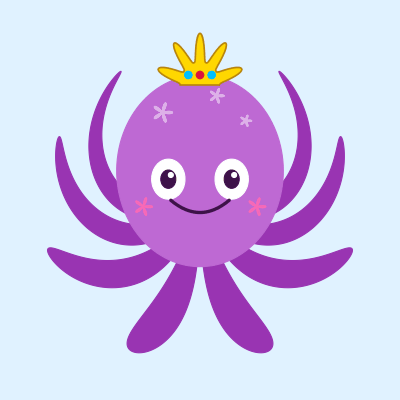

In [9]:
from IPython.display import Image
Image('octopus_swim.gif')

## 7. 海底場景：章魚家族合照 🌊

原版的「家族合照」是四張分開的圖，補交版把牠們放進同一個海底場景。除了章魚，場景裡的東西也盡量用玫瑰線或三角函數畫：

| 元素 | 數學 |
|---|---|
| 海水漸層 | `imshow` 一個從上到下 0→1 的漸層陣列，套 `Blues` 色表 |
| 沙地 | 起伏的邊界 $y = -3.2 + 0.15\sin(1.3x)$ |
| **扇形珊瑚** | **上半圓玫瑰線** $r = H\lvert\sin(k\theta)\rvert,\ 0\le\theta\le\pi$：跟觸手是同一條公式，只是翻到上面 |
| 海草 | $x = x_0 + 0.25\sin(2y + x_0)$，沿著 $y$ 往上左右擺 |
| 海星 | $r = a\,(0.55 + 0.45\cos 5\theta)$：玫瑰線 $\cos 5\theta$ 加上一個常數，就變成 5 個圓角 |
| 泡泡 | 隨機位置的小圓，`np.random.seed(7)` 讓每次執行長得一樣 |

四隻章魚用的 $k$、捲曲和表情沿用原版家族合照，另外配上不同的色相和配件。

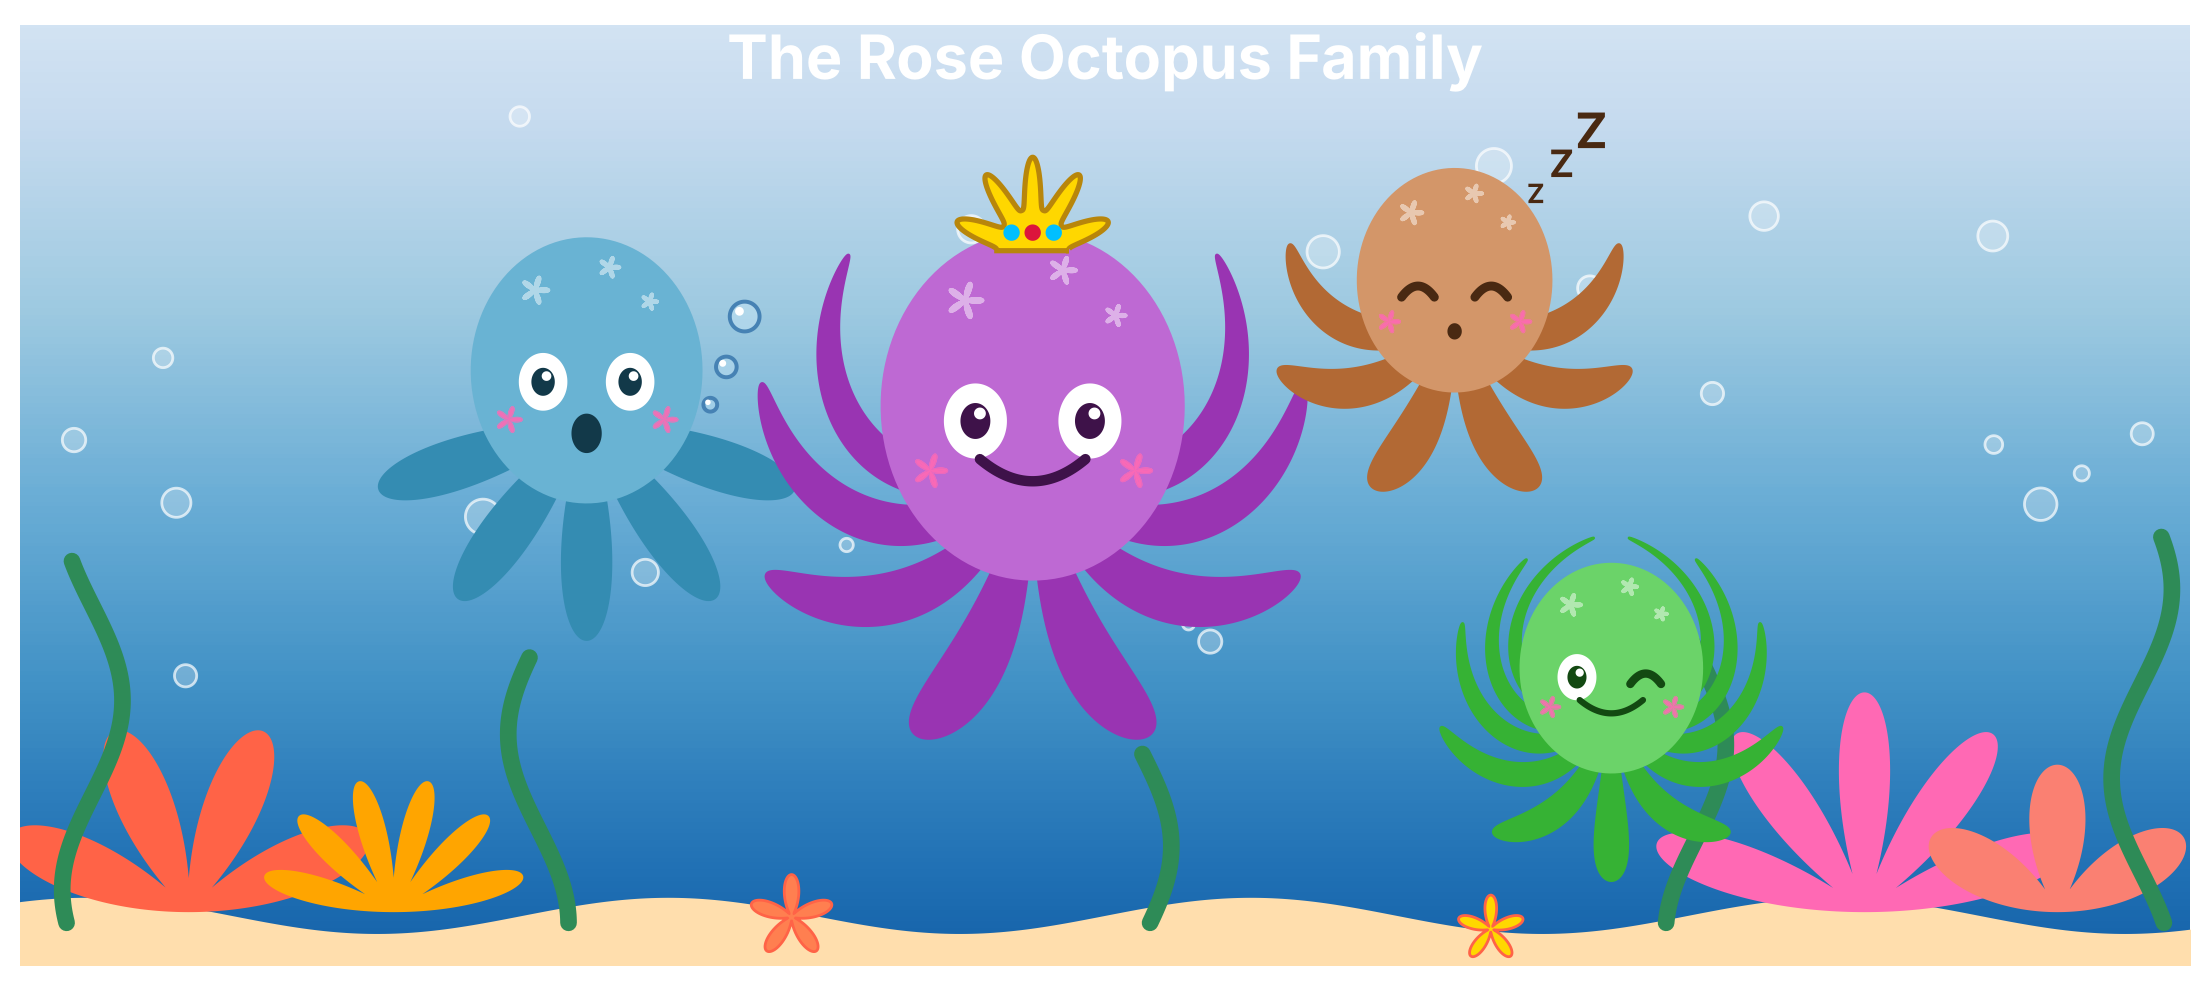

In [10]:
def coral(ax, x0, y0, H, k, color, z=1):
    th = np.linspace(0, np.pi, 600)
    r = H * np.abs(np.sin(k * th))
    ax.fill(x0 + r*np.cos(th), y0 + r*np.sin(th), color=color, zorder=z)

def seaweed(ax, x0, y0, h, color='seagreen', z=1):
    y = np.linspace(0, h, 100)
    ax.plot(x0 + 0.25*np.sin(2*y + x0), y0 + y, color=color, lw=6, solid_capstyle='round', zorder=z)

def starfish(ax, x0, y0, a, color='coral', z=2):
    th = np.linspace(0, 2*np.pi, 300)
    r = a * (0.55 + 0.45*np.cos(5*th))
    ax.fill(x0 + r*np.cos(th + np.pi/2), y0 + r*np.sin(th + np.pi/2), color=color, ec='tomato', zorder=z)

fig, ax = plt.subplots(figsize=(14, 8))
W, Y0, Y1 = 9, -3.6, 4.2
ax.imshow(np.linspace(0, 1, 256)[:, None], extent=[-W, W, Y0, Y1], aspect='auto',
          cmap='Blues', vmin=-0.3, vmax=1.3, zorder=0)
xs = np.linspace(-W, W, 400)
ax.fill_between(xs, Y0, -3.2 + 0.15*np.sin(1.3*xs), color='navajowhite', zorder=1)

for x0, H, k, c in [(-7.6, 1.6, 4, 'tomato'), (-5.9, 1.1, 6, 'orange'),
                    (6.3, 1.8, 5, 'hotpink'), (7.9, 1.2, 3, 'salmon')]:
    coral(ax, x0, -3.15, H, k, c)
for x0, h in [(-8.4, 3.0), (-4.7, 2.2), (4.9, 2.6), (8.6, 3.2), (0.3, 1.4)]:
    seaweed(ax, x0, -3.25, h)
starfish(ax, -2.6, -3.2, 0.35)
starfish(ax, 3.2, -3.3, 0.28, color='gold')

np.random.seed(7)
c = np.linspace(0, 2*np.pi, 60)
for bx, by, br in zip(np.random.uniform(-W, W, 25), np.random.uniform(-2, 4, 25), np.random.uniform(0.05, 0.15, 25)):
    ax.fill(bx + br*np.cos(c), by + br*np.sin(c), fc=(1, 1, 1, 0.25), ec=(1, 1, 1, 0.7), zorder=2)

family = [  # (cx, cy, 縮放, k, twist, 表情, 色相, 配件)
    (-4.3, 1.0, 0.95, 5, 0.00, '驚訝', 0.55, '泡泡'),
    (-0.6, 0.6, 1.25, 8, 0.30, '開心', 0.80, '皇冠'),
    ( 2.9, 1.8, 0.80, 6, 0.20, '想睡', 0.07, '無'),
    ( 4.2, -1.4, 0.75, 11, 0.45, '眨眼', 0.33, '無'),
]
for i, (cx, cy, s, k, tw, m, h, acc) in enumerate(family):
    draw_octopus(ax, k, tw, m, h, acc, cx=cx, cy=cy, s=s, z=10 + 10*i)

ax.text(0, 3.75, 'The Rose Octopus Family', ha='center', fontsize=22,
        fontweight='bold', color='white', zorder=99)
ax.set_xlim(-W, W); ax.set_ylim(Y0, Y1)
ax.set_aspect('equal'); ax.axis('off')
plt.show()

## 8. 小結

- 玫瑰線 $r = a\cos(k\theta)$ 只靠一個參數 $k$，就能產生各種對稱花瓣。
- **取下半圓**就是觸手，**取上半圓**就是珊瑚；加一個常數底座再取三次方就是皇冠；整圈的 $\cos 5\theta$ 加上一個常數就是海星。同一條公式換個範圍、加個常數，就變成完全不同的東西。
- 在角度上加 $t\,r^2\cos\theta$ 會對稱捲曲，加 $w\,r^2$ 會同向擺動；讓 $t$、$w$ 隨時間做 $\sin$／$\cos$ 變化，就成了游泳動畫。
- 配色改用 HLS 色相，一個滑桿就能換整套顏色，而且明暗關係不變。
- 把章魚寫成「可以指定位置和大小」的函式後，同一份程式碼可以用在單張圖、`interact`、動畫和場景裡。

## 心得

這次補交作業，我想在原本的章魚小怪獸上增加表情、配件、動畫和海底場景，讓它看起來更完整，也能呈現更多變化。最滿意的是游泳動畫，透過調整數學公式，讓觸手可以自然地擺動和捲曲，並且能夠無縫循環。實際製作後發現，只要善用函式和參數，就能讓同一個圖形延伸出許多不同的效果，也讓我對 Python 繪圖有了更深入的理解。

## AI 使用說明

本作業使用生成式 AI（Claude）協同製作（評分標準註三允許）。第一週原版的程式與排版由 AI 產生；這次補交要加哪四項修改（動畫、新表情與配件、色相滑桿、海底場景）是我決定的，程式與說明文字由 AI 依照這些方向撰寫，我執行並確認結果。